# 02 · Measure & Simulate 🎲
### Quantum Technologies Club Workshop · *Qiskit from zero*

[▶️ Open in Colab](https://colab.research.google.com/github/quantumtechcluburi/workshops/blob/main/qiskit-from-zero-11-10-26/notebooks/02_measure_and_simulate.ipynb) · 📥 [All workshop materials on GitHub](https://github.com/quantumtechcluburi/workshops/tree/main/qiskit-from-zero-11-10-26)

In notebook 01 we *peeked* at the qubit's arrow. A real quantum computer never lets you do that. All you can do is **measure**.
In this notebook you'll:

1. Measure qubits and see that results are **random** (but predictably random!).
2. Run circuits on a **simulator** many times ("shots") and plot **histograms**.
3. See **interference** (the reason quantum computers are interesting) with a quantum version of the double-slit experiment.

In [1]:
# ⚙️ SETUP: run this cell first (Shift + Enter)
# On Google Colab (or any fresh computer) this installs Qiskit automatically. Takes ~30 s the first time.
try:
    import qiskit, qiskit_aer, qiskit_ibm_runtime
except ImportError:
    %pip install -q qiskit qiskit-aer qiskit-ibm-runtime pylatexenc matplotlib ipywidgets
    import qiskit, qiskit_aer, qiskit_ibm_runtime

import numpy as np
import matplotlib.pyplot as plt
print("✅ Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__, "| ready to go!")

✅ Qiskit 2.6.2 | Aer 0.18.2 | ready to go!


In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.visualization import plot_histogram, plot_bloch_multivector, plot_bloch_vector
from qiskit_aer.primitives import SamplerV2 as Sampler   # the Aer simulator, in "Sampler" form

sampler = Sampler()   # our simulated quantum computer
print("Simulator ready ✅")

Simulator ready ✅


## 1 · What does "measuring" do?

Measuring a qubit asks it one yes/no question: **"are you 0 or 1?"**

* The answer is **random**, with the probabilities set by the arrow's tilt (up → always `0`, equator → 50/50, …).
* After answering, the arrow **snaps** to the pole it answered. The superposition is gone. This is often called **collapse**.

Let's measure a qubit sitting on the equator (|+⟩) five times and watch it snap:

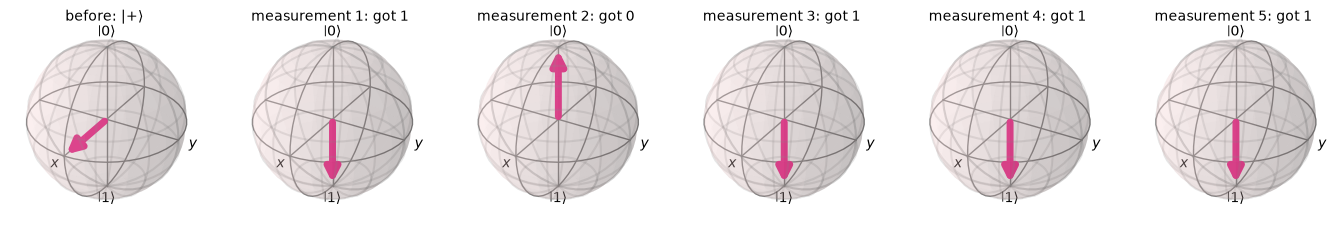

In [3]:
qc = QuantumCircuit(1)
qc.h(0)
before = Statevector(qc)

fig = plt.figure(figsize=(17, 3.4))
ax = fig.add_subplot(1, 6, 1, projection="3d")
plot_bloch_vector([1, 0, 0], ax=ax, title="before: |+⟩", font_size=10)
for i in range(5):
    outcome, after = before.measure()          # simulate one measurement
    z = 1 if outcome == "0" else -1
    ax = fig.add_subplot(1, 6, i + 2, projection="3d")
    plot_bloch_vector([0, 0, z], ax=ax, title=f"measurement {i+1}: got {outcome}", font_size=10)
plt.show()

Run the cell again and you'll get a different sequence. **Nature is rolling dice.** 🎲

## 2 · Your first measured circuit: the quantum coin 🪙

In Qiskit we add measurements with `qc.measure_all()`. Then we send the circuit to a **Sampler**, which runs it many times. Each run is called a **shot**.

> 🧠 **Simulator vs. real hardware:** the Sampler we're using is **Aer**, a simulator running on *your* computer. In notebook 04 we'll swap it for a real IBM quantum computer, and the code stays almost identical.

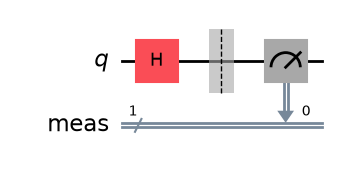

In [4]:
coin = QuantumCircuit(1)
coin.h(0)           # 50/50 superposition
coin.measure_all()  # look!
coin.draw("mpl")

In [5]:
# Flip the quantum coin 20 times, one result per shot
result = sampler.run([coin], shots=20).result()
flips = result[0].data.meas.get_bitstrings()
print("Results :", " ".join(flips))
print("As coins:", " ".join("🙂" if f == "0" else "🦅" for f in flips))

Results : 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 1 1 1 1
As coins: 🙂 🙂 🦅 🙂 🙂 🙂 🙂 🦅 🙂 🙂 🙂 🦅 🙂 🙂 🙂 🙂 🦅 🦅 🦅 🦅


Usually we don't care about the individual sequence; we care about **how often** each outcome happens. `get_counts()` tallies them and `plot_histogram` draws them:

{'0': 499, '1': 501}


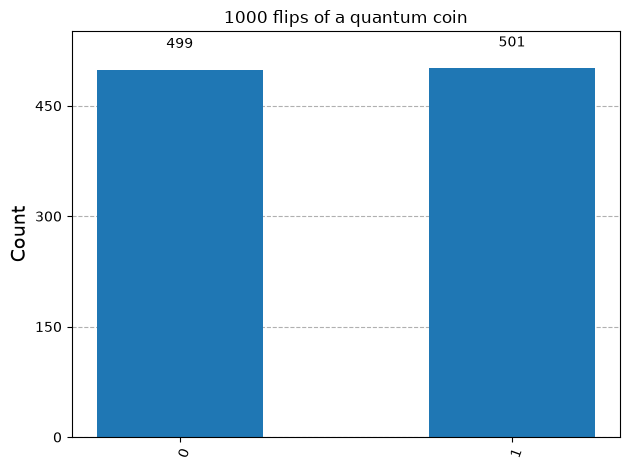

In [6]:
result = sampler.run([coin], shots=1000).result()
counts = result[0].data.meas.get_counts()
print(counts)
plot_histogram(counts, title="1000 flips of a quantum coin")

### How many shots do we need?
With few shots the results are noisy; with many they settle on the true probability (50%). Statisticians call this the *law of large numbers*:

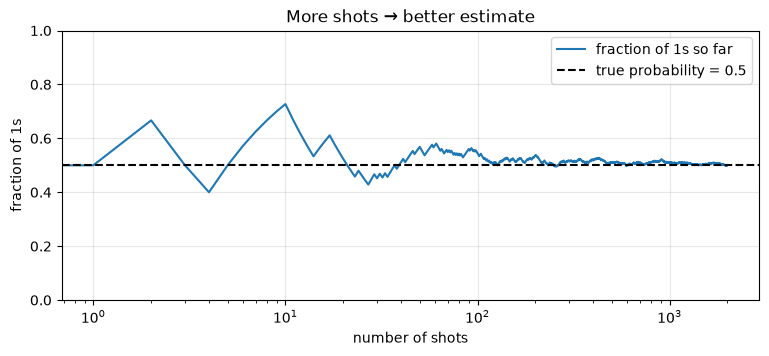

In [7]:
flips = sampler.run([coin], shots=2000).result()[0].data.meas.get_bitstrings()
ones = np.cumsum([f == "1" for f in flips]) / np.arange(1, len(flips) + 1)

plt.figure(figsize=(9, 3.5))
plt.plot(ones, label="fraction of 1s so far")
plt.axhline(0.5, color="k", ls="--", label="true probability = 0.5")
plt.xscale("log"); plt.ylim(0, 1)
plt.xlabel("number of shots"); plt.ylabel("fraction of 1s"); plt.legend(); plt.grid(alpha=0.3)
plt.title("More shots → better estimate")
plt.show()

## 3 · A loaded quantum coin 🎯

With `RY(θ)` we can tilt the arrow by any amount and make a coin that's biased however we want.
Theory (from the Bloch sphere) says $P(1) = \sin^2(\theta/2)$. Let's check it **experimentally**.

We use a `Parameter` (a placeholder angle) so we can run the *same circuit* for 25 different angles in one go:

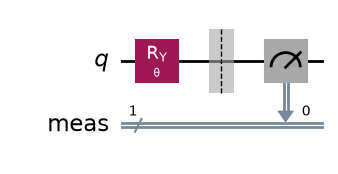

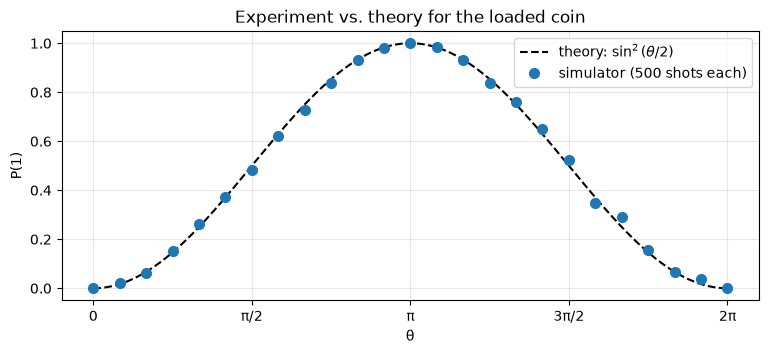

In [8]:
theta = Parameter("θ")
loaded = QuantumCircuit(1)
loaded.ry(theta, 0)
loaded.measure_all()
display(loaded.draw("mpl"))

angles = np.linspace(0, 2 * np.pi, 25)
job = sampler.run([(loaded, angles.reshape(-1, 1))], shots=500)   # one job, 25 angles
data = job.result()[0].data.meas
p1 = [data.get_counts(i).get("1", 0) / 500 for i in range(len(angles))]

fine = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(9, 3.5))
plt.plot(fine, np.sin(fine / 2) ** 2, "k--", label=r"theory: $\sin^2(\theta/2)$")
plt.plot(angles, p1, "o", ms=7, label="simulator (500 shots each)")
plt.xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi], ["0", "π/2", "π", "3π/2", "2π"])
plt.xlabel("θ"); plt.ylabel("P(1)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Experiment vs. theory for the loaded coin")
plt.show()

## 4 · Interference: the quantum magic trick 🪄

Remember from notebook 01: **H then H brings the qubit back to |0⟩**. So if we measure after two H gates, we should *always* get `0`.

But what if we **sneak a peek** in the middle? Common sense says peeking shouldn't matter… let's test both:

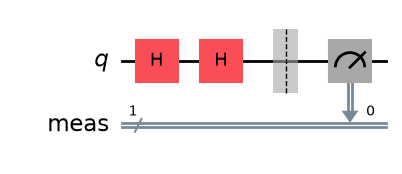

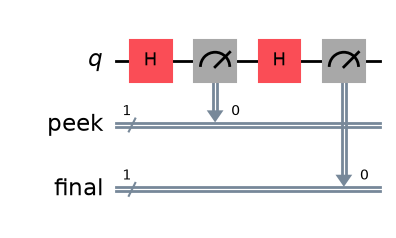

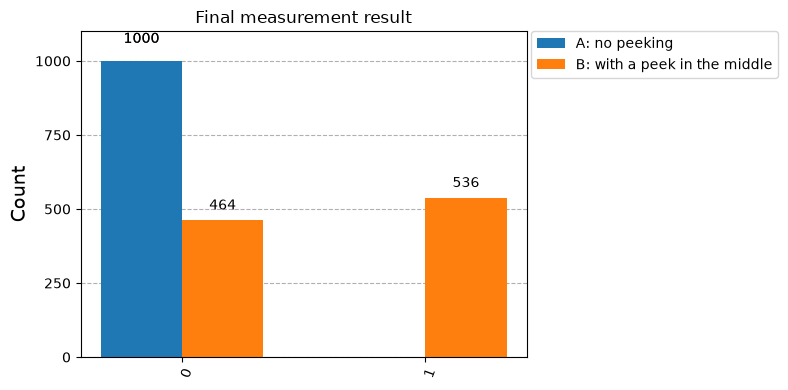

In [9]:
# Experiment A: H, H, measure  (no peeking)
no_peek = QuantumCircuit(1)
no_peek.h(0)
no_peek.h(0)
no_peek.measure_all()

# Experiment B: H, PEEK (measure), H, measure
q = QuantumRegister(1, "q")
peek_bit, final_bit = ClassicalRegister(1, "peek"), ClassicalRegister(1, "final")
peek = QuantumCircuit(q, peek_bit, final_bit)
peek.h(0)
peek.measure(0, peek_bit[0])     # 👀 the sneaky peek
peek.h(0)
peek.measure(0, final_bit[0])

display(no_peek.draw("mpl"), peek.draw("mpl"))

res = sampler.run([no_peek, peek], shots=1000).result()
counts_A = res[0].data.meas.get_counts()
counts_B = res[1].data.final.get_counts()
plot_histogram([counts_A, counts_B], legend=["A: no peeking", "B: with a peek in the middle"],
               title="Final measurement result", figsize=(8, 4))

🤯 **Just looking changes the outcome.**

* **Without peeking**, the two "paths" (through `0` and through `1`) **interfere**: the paths leading to `1` *cancel out* (one carries a + sign, the other a − sign), and the paths to `0` *add up*. Result: always `0`.
* **With a peek**, the qubit is forced to pick a path, nothing can interfere, and we get plain 50/50 coin-flip randomness.

This is exactly the logic of the famous **double-slit experiment**: one particle going through *both* slits produces an interference pattern… unless you check which slit it went through.

## 5 · Quantum double-slit (Mach-Zehnder interferometer) 🌊
*Adapted from the club's earlier TwoSlit notebook.*

Make the "two paths" picture concrete:
1. `H` = a beam splitter: the particle takes **both paths** at once.
2. `P(φ)` = one path is a little longer than the other → it picks up an extra **phase** φ.
3. `H` = the paths are recombined, then we see where the particle lands (`0` or `1`).

Changing φ is like moving along the screen in the double-slit experiment: we should see **bright and dark fringes**. Theory says $P(0) = \cos^2(\varphi/2)$.

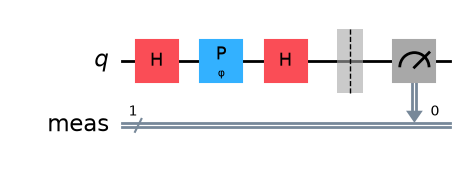

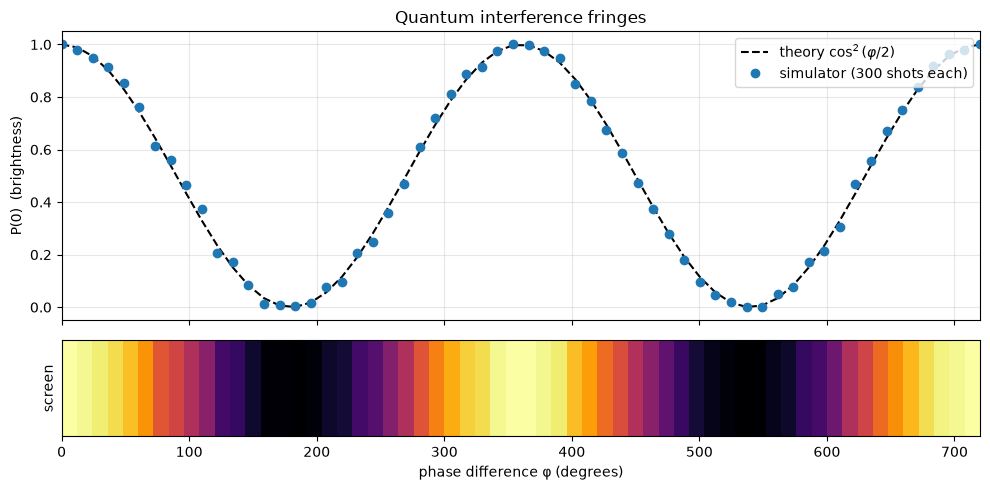

In [10]:
phi = Parameter("φ")
mz = QuantumCircuit(1)
mz.h(0)          # beam splitter: take both paths
mz.p(phi, 0)     # extra path length = phase shift
mz.h(0)          # recombine the paths
mz.measure_all()
display(mz.draw("mpl"))

phases = np.linspace(0, 4 * np.pi, 60)
shots = 300
data = sampler.run([(mz, phases.reshape(-1, 1))], shots=shots).result()[0].data.meas
p0 = np.array([data.get_counts(i).get("0", 0) / shots for i in range(len(phases))])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
ax1.plot(np.degrees(phases), np.cos(phases / 2) ** 2, "k--", label=r"theory $\cos^2(\varphi/2)$")
ax1.plot(np.degrees(phases), p0, "o", label=f"simulator ({shots} shots each)")
ax1.set_ylabel("P(0)  (brightness)"); ax1.legend(loc="upper right"); ax1.grid(alpha=0.3)
ax1.set_title("Quantum interference fringes")
ax2.imshow(p0[np.newaxis, :], aspect="auto", cmap="inferno",
           extent=[0, np.degrees(phases[-1]), 0, 1])         # what the "screen" would look like
ax2.set_yticks([]); ax2.set_xlabel("phase difference φ (degrees)"); ax2.set_ylabel("screen")
plt.tight_layout(); plt.show()

Bright fringes where the paths add up, dark fringes where they cancel, all from **one single qubit**. 🌈

### What's happening on the Bloch sphere?
Here's the same circuit for φ = 45°, step by step (the original TwoSlit notebook did this with rotation matrices; Qiskit can do it for us):

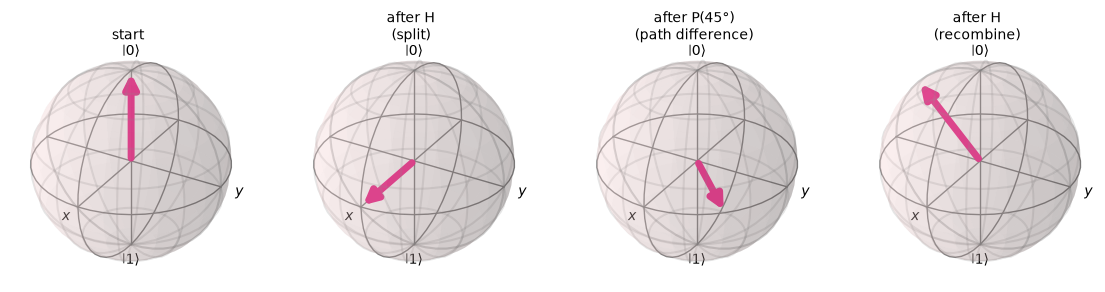

In [11]:
def bloch_xyz(state):
    return [np.real(state.expectation_value(SparsePauliOp(p))) for p in "XYZ"]

steps = [("start", []), ("after H\n(split)", ["h"]), ("after P(45°)\n(path difference)", ["h", "p"]),
         ("after H\n(recombine)", ["h", "p", "h"])]
fig = plt.figure(figsize=(14, 3.6))
for i, (label, gates) in enumerate(steps):
    c = QuantumCircuit(1)
    for g in gates:
        c.h(0) if g == "h" else c.p(np.pi / 4, 0)
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    plot_bloch_vector(bloch_xyz(Statevector(c)), ax=ax, title=label, font_size=10)
plt.show()

### Bonus: the other primitive, `Estimator`
The **Sampler** gives you *counts*. Qiskit also has an **Estimator**, which directly gives the *average value* of a measurement (here ⟨Z⟩ = P(0) − P(1), ranging from +1 to −1). The original TwoSlit notebook used this one. Same fringes, different units:

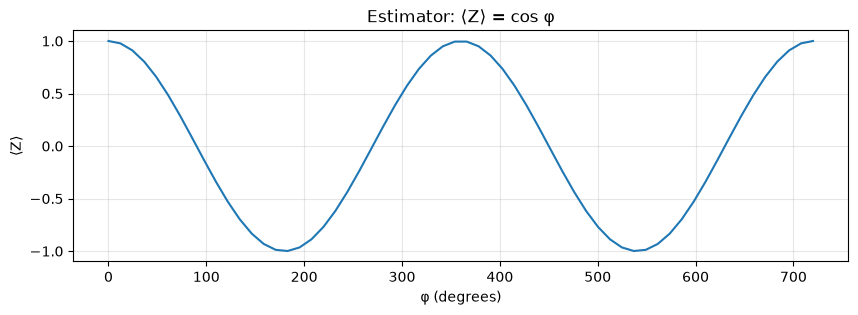

In [12]:
from qiskit.primitives import StatevectorEstimator   # exact, built into Qiskit

mz_no_meas = mz.remove_final_measurements(inplace=False)   # Estimator doesn't want measurements
evs = StatevectorEstimator().run([(mz_no_meas, SparsePauliOp("Z"), phases.reshape(-1, 1))]).result()[0].data.evs

plt.figure(figsize=(10, 3))
plt.plot(np.degrees(phases), evs)
plt.xlabel("φ (degrees)"); plt.ylabel("⟨Z⟩"); plt.grid(alpha=0.3); plt.title("Estimator: ⟨Z⟩ = cos φ")
plt.show()

## 6 · Many qubits, many outcomes (and a gotcha!) ⚠️

With *n* qubits there are $2^n$ possible outcomes. Qiskit writes results as bitstrings with **qubit 0 on the RIGHT** (like place values in a binary number). This trips up *everyone* the first time:

In [13]:
qc = QuantumCircuit(3)
qc.x(0)            # flip ONLY qubit 0
qc.measure_all()
counts = sampler.run([qc], shots=100).result()[0].data.meas.get_counts()
print(counts, "  ← qubit 0 is the rightmost character! (read as  q2 q1 q0)")

{'001': 100}   ← qubit 0 is the rightmost character! (read as  q2 q1 q0)


### 🎲 A true quantum random-number generator
Put 3 qubits in superposition and measure: you get one of 8 outcomes (`000`…`111` = 0…7), each with equal probability. Unlike `random.random()` on your laptop, this randomness is (on real hardware) fundamentally unpredictable.

12 quantum rolls of an 8-sided die: [1, 1, 8, 4, 2, 8, 5, 4, 1, 6, 5, 1]


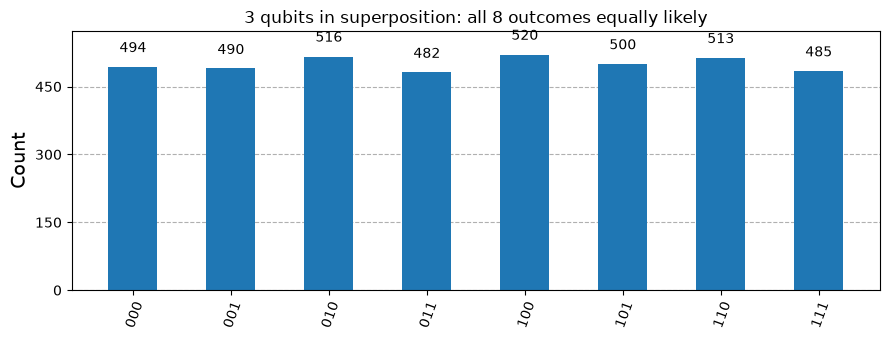

In [14]:
dice = QuantumCircuit(3)
dice.h([0, 1, 2])
dice.measure_all()

rolls = sampler.run([dice], shots=12).result()[0].data.meas.get_bitstrings()
print("12 quantum rolls of an 8-sided die:", [int(b, 2) + 1 for b in rolls])

counts = sampler.run([dice], shots=4000).result()[0].data.meas.get_counts()
plot_histogram(counts, title="3 qubits in superposition: all 8 outcomes equally likely", figsize=(9, 3.5))

---
## 🏆 Challenges

**C1.** Build a coin that lands on `1` about **90%** of the time. Run 1000 shots and plot the histogram.

**C2.** In the "peek" experiment, what happens if you peek with a qubit that starts as |1⟩ (add `x(0)` at the start)? Predict first, then run.

**C3.** Make a circuit with 2 qubits whose result is **always `10`**. (Careful with the ordering gotcha!)

**C4. ⭐** In the interferometer, what phase φ makes the particle land on `1` *every* time? Check by running `mz` with just that value.

<details><summary>💡 Click for solutions</summary>

* **C1:** $\sin^2(\theta/2)=0.9 \Rightarrow \theta = 2\arcsin(\sqrt{0.9}) \approx 2.50$ → `qc.ry(2.50, 0); qc.measure_all()`
* **C2:** Without a peek: always back to `1`. With a peek: still 50/50, because peeking destroys interference no matter where you start.
* **C3:** Flip **qubit 1** (the second from the right): `qc = QuantumCircuit(2); qc.x(1); qc.measure_all()`
* **C4:** φ = π (180°): `sampler.run([(mz, [np.pi])], shots=100).result()[0].data.meas.get_counts()` → `{'1': 100}`, a perfectly dark fringe for `0`.
</details>

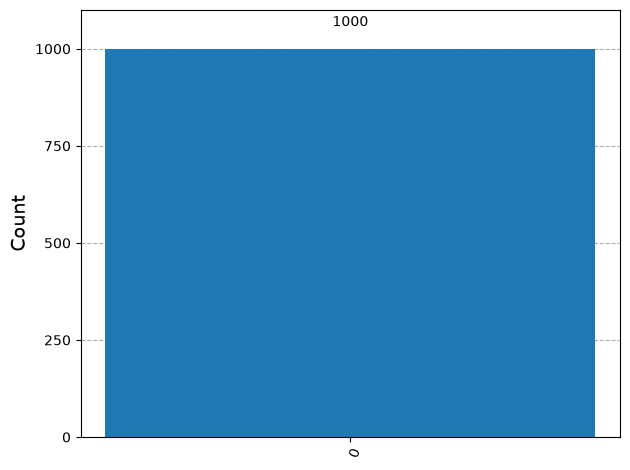

In [15]:
# ✍️ Your playground
qc = QuantumCircuit(1)

qc.measure_all()
counts = sampler.run([qc], shots=1000).result()[0].data.meas.get_counts()
plot_histogram(counts)

---
## ✅ Recap
* **Measuring** gives a random `0`/`1` and **collapses** the qubit to the answer.
* A **Sampler** runs the circuit many **shots**; `get_counts()` + `plot_histogram()` show the statistics.
* **Interference**: paths can add up or **cancel out**, but only if nobody is looking. This is what quantum algorithms exploit.
* Bitstrings are read **right-to-left**: qubit 0 is the rightmost.

👉 **Next: `03_q_is_for_quantum.ipynb`**: entanglement, with balls and mist.